In [15]:
from pathlib import Path
import sys
import importlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import display
import ipywidgets as widgets

ROOT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils" / "kmeans_smote_utils.py").exists()),
    None
)
if ROOT_DIR is None:
    raise FileNotFoundError("Não encontrei a pasta 'utils'. Verifique onde kmeans_smote_utils.py está salvo.")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import utils.kmeans_smote_utils as km_utils
importlib.reload(km_utils)

from utils.kmeans_smote_utils import (
    load_processed_data,
    fit_kmeans_scenarios,
    fit_smote_mrs_scenarios,
    compare_scenarios,
    plot_metric_comparison,
    plot_resampling_counts,
    plot_contingency_heatmap,
    plot_pca_comparison,
    plot_feature_boxplots,
    plot_voronoi_comparison,
    clustering_metrics,
)

from sklearn.decomposition import PCA

candidates = [
    ROOT_DIR / "data" / "processed",
    Path.cwd() / "data" / "processed",
    Path.cwd().parent / "data" / "processed",
    Path.cwd().parent.parent / "data" / "processed",
]

DATA_DIR = next((p for p in candidates if (p / "X_train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Não encontrei data/processed/X_train.csv. Ajuste DATA_DIR manualmente.")

sns.set_theme(style="whitegrid", context="notebook")
X_train, X_test, y_train, y_test = load_processed_data(DATA_DIR)
print(f"Dados: X_train={X_train.shape}, X_test={X_test.shape}")

Dados: X_train=(10648, 24), X_test=(4564, 24)


In [16]:
important_variables = [
    "FOLATE",
    "TSD",
    "HGB",
    "B12",
    "GENDER",
    "FERRITTE",
    "HCT",
    "RBC",
    "SD",
    "MCH"
]

X_train = X_train[important_variables].copy()
X_test  = X_test[important_variables].copy()

In [17]:
N_CLUSTERS = 5
RANDOM_STATE = 2005
baseline = fit_kmeans_scenarios(
    X_train,
    X_test,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
)

In [18]:
metrics_base = clustering_metrics(baseline, y_test, "Sem SMOTE")
display(metrics_base.style.format({c: "{:.4f}" for c in metrics_base.columns if c not in ["Cenário", "Scaler"]}))

,Cenário,Scaler,ARI,NMI,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,Sem SMOTE,standard,0.3279,0.3414,0.1805,1.6189,891.8744
1,Sem SMOTE,minmax,0.2862,0.3388,0.2495,1.3374,5527.5881
2,Sem SMOTE,robust,0.0858,0.0431,0.4959,1.2144,2219.7432
3,Sem SMOTE,quantile,0.2077,0.2727,0.2048,1.6859,4969.8329


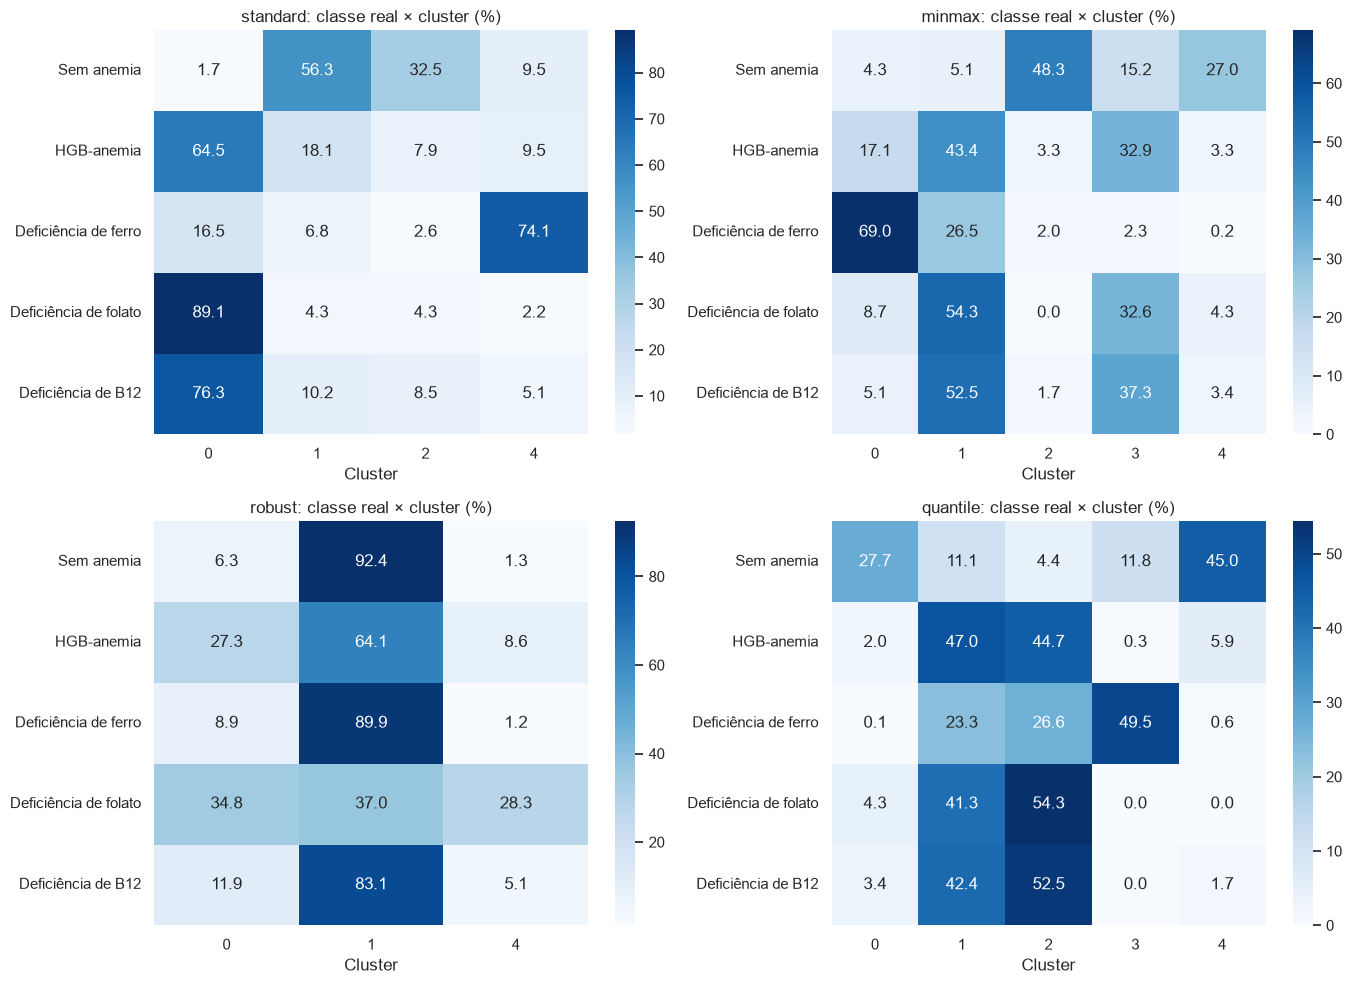

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, item) in zip(axes.flat, baseline.items()):
    plot_contingency_heatmap(item, y_test, normalize=True, ax=ax)
    ax.set_title(f"{name}: classe real × cluster (%)")
plt.tight_layout()
plt.show()

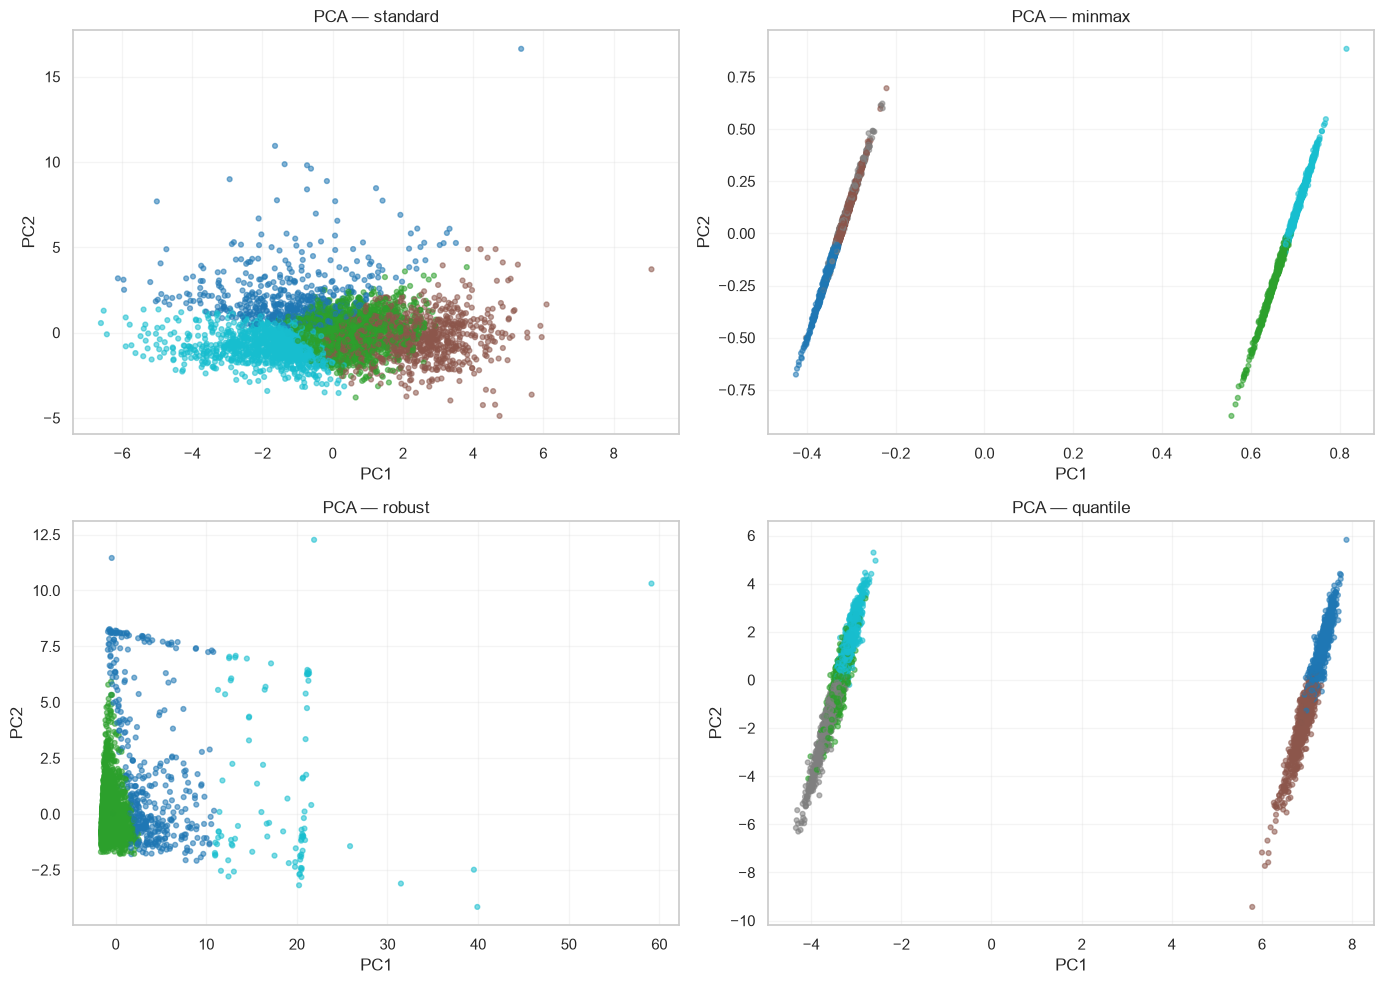

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, item) in zip(axes.flat, baseline.items()):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(item["X_train_scaled"])
    coords = pca.transform(item["X_test_scaled"])
    ax.scatter(coords[:, 0], coords[:, 1], c=item["clusters_test"], cmap="tab10", s=12, alpha=.55)
    ax.set_title(f"PCA — {name}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

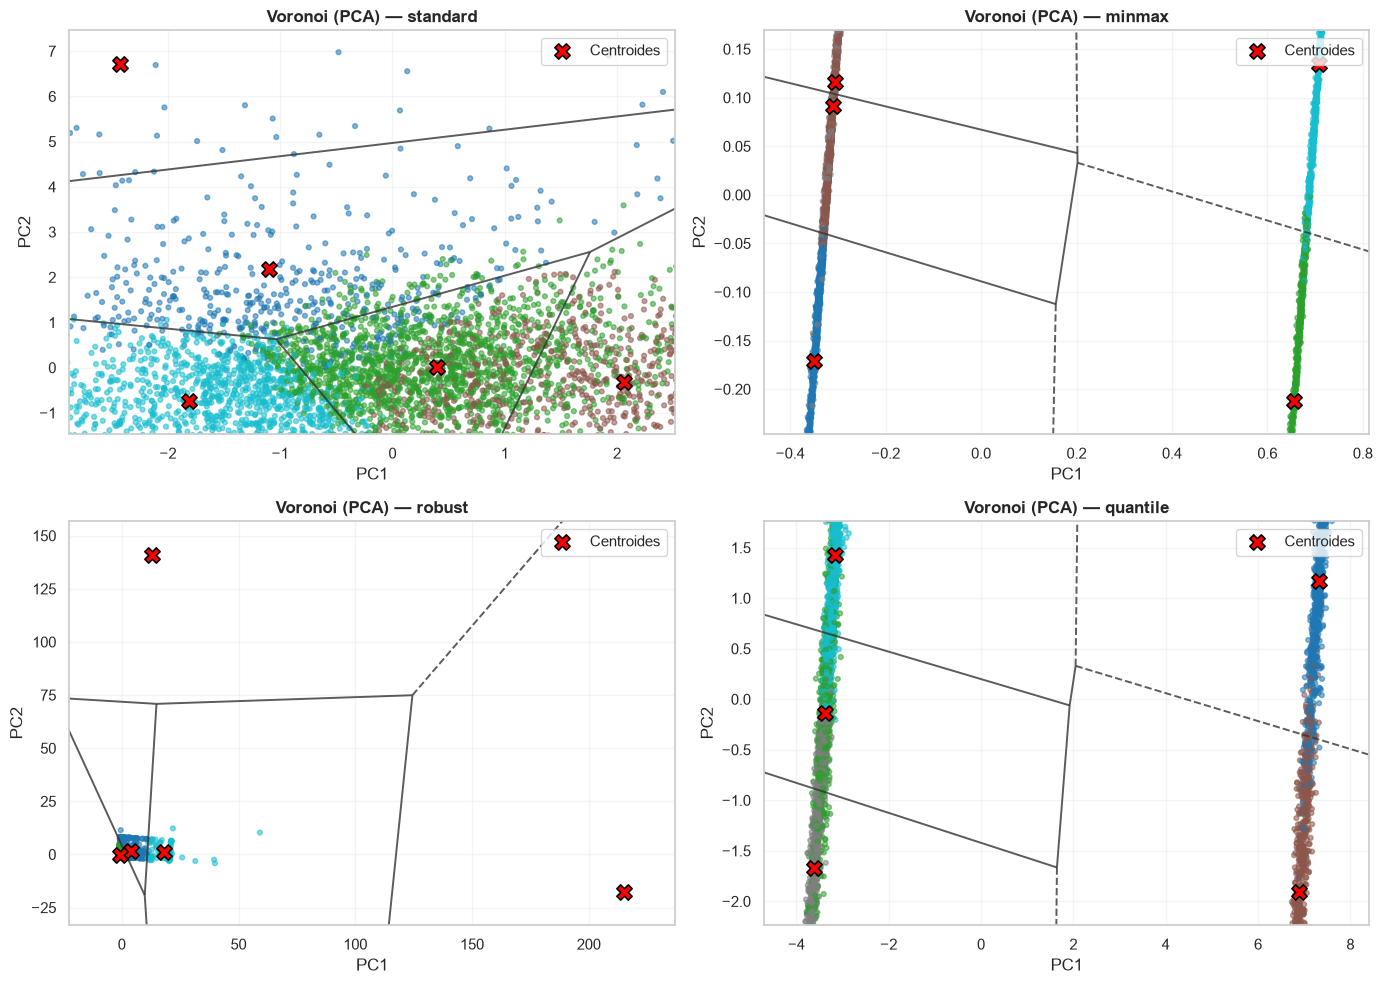

In [21]:
km_utils.plot_voronoi_grid(baseline, random_state=RANDOM_STATE)
plt.show()